# 02 · Build the evaluation sets

Two benchmarks with the same queries, positives and dev/test split. Only the negatives differ.
- **Shared negative pool.** Other queries' references that were published before the query paper, excluding the query's own references and any paper sharing an author with it.
- **`random`.** Negatives sampled uniformly from that pool.
- **`concept` (harder).** Negatives must share at least one of the query's top-5 OpenAlex concepts. When too few match, the remainder is topped up with random negatives, and the count is recorded.

Each query has n positives and 2n negatives. All randomness is seeded through sha256 (v1 used Python's salted `hash()`, audit F8).

In [1]:
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore", message="IProgress not found")

RESEARCH = Path.cwd().parent if Path.cwd().name == "v2" else Path.cwd()
sys.path.insert(0, str(RESEARCH))

import pandas as pd
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

from src.figures import save, setup_style
setup_style()

In [2]:
SEED = 0

In [3]:
from src.pipeline_v2 import build, fetch_all

queries, papers, missing = fetch_all()
datasets = {bench: build(bench, queries, papers, seed=SEED) for bench in ("random", "concept")}

### Summary

In [4]:
import numpy as np

rows = []
for bench, ds in datasets.items():
    npos = np.array([len(s["positives"]) for s in ds["sets"]])
    nneg = np.array([len(s["negatives"]) for s in ds["sets"]])
    topped = sum(s["n_neg_concept_matched"] is not None and s["n_neg_concept_matched"] < len(s["negatives"])
                 for s in ds["sets"])
    rows.append({"bench": bench, "queries": len(ds["sets"]), "dropped": len(ds["dropped"]),
                 "dev": sum(v == "dev" for v in ds["splits"].values()),
                 "test": sum(v == "test" for v in ds["splits"].values()),
                 "positives (median)": np.median(npos), "candidates (max)": (npos + nneg).max(),
                 "negatives = 2n": bool((nneg == 2 * npos).all()), "topped up": topped,
                 "papers": len(ds["papers"])})
display(pd.DataFrame(rows))
display(pd.DataFrame(datasets["random"]["dropped"]))

,bench,queries,dropped,dev,test,positives (median),candidates (max),negatives = 2n,topped up,papers
0,random,168,6,50,118,7.0,42,True,0,1361
1,concept,168,6,50,118,7.0,42,True,7,1353


,pi_id,reason
0,https://openalex.org/W3031507022,query missing or without title/abstract/date
1,https://openalex.org/W3084096028,query missing or without title/abstract/date
2,https://openalex.org/W3114649133,2 eligible positives
3,https://openalex.org/W3144489365,query missing or without title/abstract/date
4,https://openalex.org/W3146347245,query missing or without title/abstract/date
5,https://openalex.org/W3216835185,query missing or without title/abstract/date


### Sanity checks

Each check guards against one of the audit findings. A failing check raises an error.

In [5]:
from src.eval_v2 import build_eval_sets, candidate_order

def check(name, ok):
    print(("PASS  " if ok else "FAIL  ") + name)
    assert ok, name

for bench, ds in datasets.items():
    print(f"--- {bench}")
    P = ds["papers"]
    check("F6: every paper record carries its own id", all(pid == r["id"] for pid, r in P.items()))
    check("F4: all candidates have identical fields", len({tuple(sorted(r)) for r in P.values()}) == 1)
    check("negatives published before the query",
          all(P[n]["publication_date"] < s["pi_date"] for s in ds["sets"] for n in s["negatives"]))
    check("no negative is one of the query's references",
          all(not set(s["negatives"]) & set(s["positives"]) for s in ds["sets"]))
    check("no negative shares an author with the query",
          all(not set(P[s["pi_id"]]["author_ids"]) & set(P[n]["author_ids"]) for s in ds["sets"] for n in s["negatives"]))
    again = build_eval_sets(queries, papers, seed=SEED, bench=bench)
    check("F8: rebuilding gives identical pools", again["sets"] == ds["sets"])
    pos_rel = [candidate_order(s, "shuffled", 0).index(c) / (len(s["positives"]) + len(s["negatives"]) - 1)
               for s in ds["sets"] for c in s["positives"]]
    check(f"F1: shuffled positives sit mid-list on average ({np.mean(pos_rel):.3f})", abs(np.mean(pos_rel) - 0.5) < 0.03)
    orig = [candidate_order(s, "original", 0)[: len(s["positives"])] == s["positives"] for s in ds["sets"]]
    check("'original' order reproduces v1 (positives first) for the position-bias experiment", all(orig))

--- random
PASS  F6: every paper record carries its own id
PASS  F4: all candidates have identical fields
PASS  negatives published before the query
PASS  no negative is one of the query's references
PASS  no negative shares an author with the query
PASS  F8: rebuilding gives identical pools
PASS  F1: shuffled positives sit mid-list on average (0.496)
PASS  'original' order reproduces v1 (positives first) for the position-bias experiment
--- concept
PASS  F6: every paper record carries its own id
PASS  F4: all candidates have identical fields
PASS  negatives published before the query
PASS  no negative is one of the query's references
PASS  no negative shares an author with the query
PASS  F8: rebuilding gives identical pools


PASS  F1: shuffled positives sit mid-list on average (0.496)
PASS  'original' order reproduces v1 (positives first) for the position-bias experiment


### Are positives and negatives distinguishable by form?

In v1, negatives had no concept tags, which the LLM could exploit (F4). Field presence and length should now match between positives and negatives. Topical overlap with the query is what the two benchmarks deliberately vary.

In [6]:
rows = []
for bench, ds in datasets.items():
    P = ds["papers"]
    for role in ("positives", "negatives"):
        ids = [(s["pi_id"], c) for s in ds["sets"] for c in s[role]]
        top = lambda pid: set(P[pid]["concepts_array"][:5])
        rows.append({"bench": bench, "role": role,
                     "has concepts": np.mean([bool(P[c]["concepts_array"]) for _, c in ids]),
                     "abstract chars": np.mean([len(P[c]["abstract"]) for _, c in ids]),
                     "title chars": np.mean([len(P[c]["title"]) for _, c in ids]),
                     "shares a top-5 concept with query": np.mean([bool(top(q) & top(c)) for q, c in ids])})
pd.DataFrame(rows).round(3)

,bench,role,has concepts,abstract chars,title chars,shares a top-5 concept with query
0,random,positives,1.0,1462.329,82.941,0.735
1,random,negatives,1.0,1409.804,82.809,0.295
2,concept,positives,1.0,1462.329,82.941,0.735
3,concept,negatives,1.0,1501.483,83.052,0.977


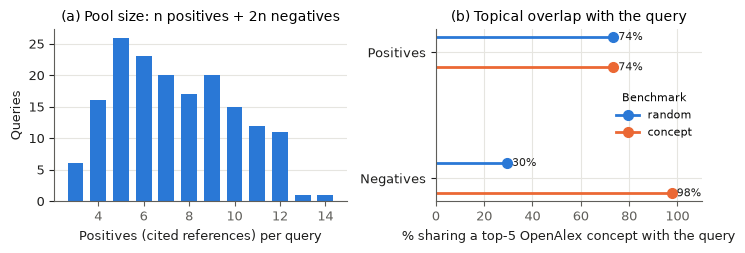

In [7]:
from src.figures import fig_dataset_overview
save(fig_dataset_overview(datasets), "02_dataset_overview")

**Figure (02_dataset_overview).** (a) Positives per query; every query also gets 2n negatives. (b) Share of candidates that share a top-5 OpenAlex concept with the query. In the random benchmark, negatives are topically far from the query. The concept benchmark closes most of that gap.

### Data quality notes

OpenAlex dates are sometimes wrong. For example, a 2011 paper is dated 2021 because a repository copy was indexed. A few positives are therefore dated on or after their query.

In [8]:
ds = datasets["random"]; P = ds["papers"]
late = [(s["pi_id"], c) for s in ds["sets"] for c in s["positives"] if P[c]["publication_date"] >= s["pi_date"]]
print(f"positives dated on/after their query: {len(late)} of {sum(len(s['positives']) for s in ds['sets'])}")

positives dated on/after their query: 21 of 1247


### Findings

- **Size.** 168 of 174 queries remain. Five lack an abstract or date in OpenAlex and one has only two usable references. Each benchmark has 50 dev and 118 test queries, 3–14 positives per query (median 7) and up to 42 candidates.
- **Checks.** All sanity checks pass on both benchmarks. Every record carries its own id (F6), fields are identical (F4), pools rebuild identically (F8), shuffled positives sit mid-list (mean relative position 0.496; F1), and negatives predate the query and share no authors with it.
- **Form.** Positives and negatives no longer differ in form. Both always have concepts, and abstracts average about 1,460 vs 1,410–1,500 characters.
- **Difficulty is what the two benchmarks vary.** In `random`, only 30% of negatives share a top-5 concept with the query, against 74% of positives, so lexical overlap alone separates them. In `concept`, 98% of negatives share one, which is *more* than the positives. Topical overlap now points the wrong way, and a method has to judge relevance beyond shared field labels. Seven `concept` queries had too few matching negatives and were topped up with random ones.
- **Data quality.** OpenAlex dates are imperfect: 21 of 1,247 positives are dated on or after their citing paper (e.g. a 2011 paper indexed with a 2021 repository date). This affects only the date filter for negatives and the contamination split.